# TGA-SV Simulation Validation

This notebook validates simulated data generated from the TGA-SV model using the parameter values from the paper.

The objectives are to:
- verify the simulated innovations;
- inspect the latent volatility process;
- illustrate volatility clustering;
- check the persistence induced by $\phi$;
- visualize the asymmetric response function $f(\epsilon_t)$.

## 1. Load simulated data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/simulated_tga_sv_normal_T500.csv")

df.head()

## 2. Basic simulation checks

We verify that the simulated innovations approximately satisfy

$$
E[\epsilon_t]=0,
\qquad
\operatorname{Var}(\epsilon_t)=1,
$$

and

$$
E[\eta_t]=0,
\qquad
\operatorname{Var}(\eta_t)=\sigma_\eta^2.
$$

In [2]:
print(df.shape)
print()
print(df.describe())

(500, 8)

                t           h      sigma2       sigma     epsilon         eta  \
count  500.000000  500.000000  500.000000  500.000000  500.000000  500.000000   
mean   250.500000    1.780393    9.145000    2.712918   -0.028910    0.000285   
std    144.481833    0.917539    9.930024    1.337406    0.986905    0.216884   
min      1.000000   -0.368767    0.691587    0.831617   -3.148945   -0.529532   
25%    125.750000    1.106478    3.023716    1.738880   -0.681648   -0.147512   
50%    250.500000    1.695164    5.447582    2.334001   -0.013254    0.002831   
75%    375.250000    2.463227   11.742644    3.426754    0.586463    0.142621   
max    500.000000    4.335278   76.346165    8.737629    2.693698    0.571175   

        f_epsilon      Return  
count  500.000000  500.000000  
mean     0.036476   -0.114363  
std      0.126005    2.825912  
min     -0.079553  -16.913173  
25%     -0.067628   -1.594239  
50%     -0.007403   -0.029221  
75%      0.112908    1.478055  
max 

In [3]:
print("Mean epsilon:", df["epsilon"].mean())
print("Var epsilon :", df["epsilon"].var(ddof=0))

print("Mean eta    :", df["eta"].mean())
print("Var eta     :", df["eta"].var(ddof=0))

print("Mean h      :", df["h"].mean())
print("Mean Return :", df["Return"].mean())

Mean epsilon: -0.028909531078003654
Var epsilon : 0.9720331646322353
Mean eta    : 0.00028454591825412544
Var eta     : 0.04694451302695025
Mean h      : 1.7803930032650208
Mean Return : -0.11436294540032847


## 3. Simulated returns

The observed variable of the model is

$$
y_t = e^{h_t/2}\epsilon_t.
$$

The return series should exhibit periods of relatively low and high volatility rather than constant variance over time.

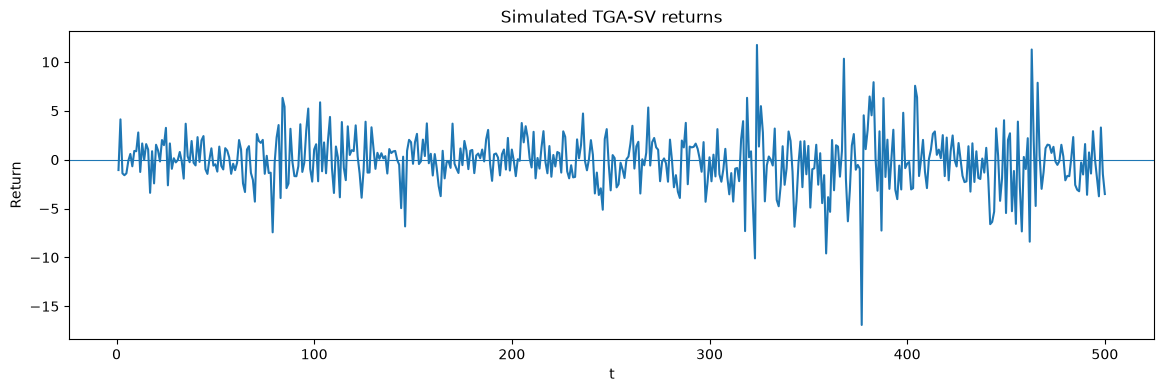

In [4]:
plt.figure(figsize=(14, 4))

plt.plot(df["t"], df["Return"])

plt.axhline(0, linewidth=0.8)

plt.xlabel("t")
plt.ylabel("Return")
plt.title("Simulated TGA-SV returns")

plt.show()

## 4. Latent volatility

The latent state $h_t$ represents log-variance:

$$
h_t = \log(\sigma_t^2).
$$

Therefore,

$$
\sigma_t^2=e^{h_t},
\qquad
\sigma_t=e^{h_t/2}.
$$

Unlike the returns, $h_t$ and $\sigma_t$ would not be observed in a real financial dataset. They are available here because the data are simulated.

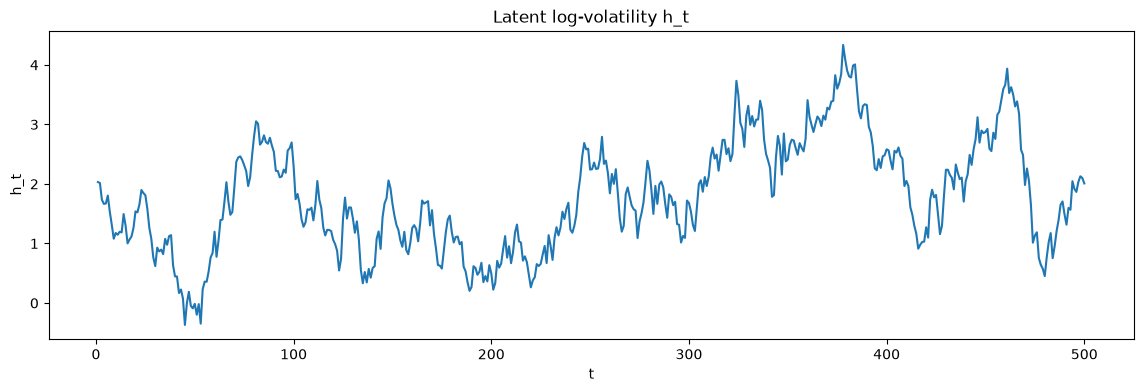

In [5]:
plt.figure(figsize=(14, 4))

plt.plot(df["t"], df["h"])

plt.xlabel("t")
plt.ylabel("h_t")
plt.title("Latent log-volatility h_t")

plt.show()

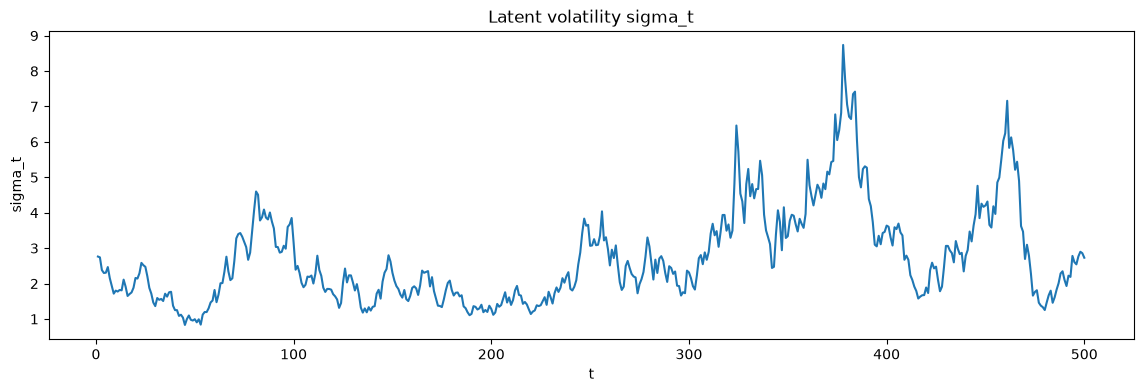

In [6]:
plt.figure(figsize=(14, 4))

plt.plot(df["t"], df["sigma"])

plt.xlabel("t")
plt.ylabel("sigma_t")
plt.title("Latent volatility sigma_t")

plt.show()

## 5. Returns and latent volatility

Since

$$
y_t=\sigma_t\epsilon_t,
$$

large absolute returns should occur more frequently during periods of high latent volatility.

However, a high value of $\sigma_t$ does not necessarily imply a large return because the realized return also depends on $\epsilon_t$.

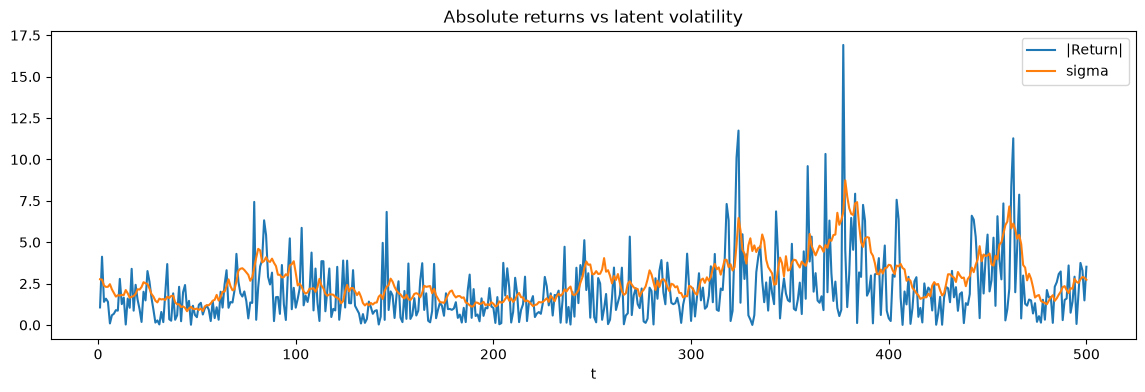

In [7]:
plt.figure(figsize=(14, 4))

plt.plot(df["t"], np.abs(df["Return"]), label="|Return|")
plt.plot(df["t"], df["sigma"], label="sigma")

plt.xlabel("t")
plt.title("Absolute returns vs latent volatility")
plt.legend()

plt.show()

### Relationship between absolute returns and volatility

We examine the relationship between

$$
|y_t|
$$

and the latent volatility

$$
\sigma_t.
$$

A positive association is expected, although the relationship is not deterministic because of the innovation $\epsilon_t$.

In [8]:
corr = np.corrcoef(
    np.abs(df["Return"]),
    df["sigma"]
)[0, 1]

print("Corr(|Return|, sigma) =", corr)

Corr(|Return|, sigma) = 0.42719283282847537


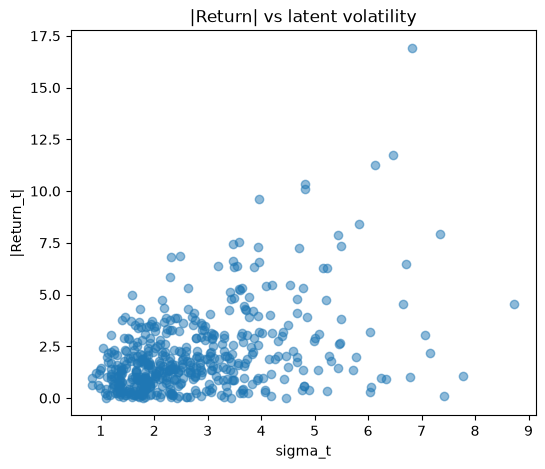

In [9]:
plt.figure(figsize=(6, 5))

plt.scatter(
    df["sigma"],
    np.abs(df["Return"]),
    alpha=0.5
)

plt.xlabel("sigma_t")
plt.ylabel("|Return_t|")
plt.title("|Return| vs latent volatility")

plt.show()

## 6. Volatility clustering

A stochastic volatility model should generate approximately uncorrelated returns while producing persistent dependence in their magnitude.

We therefore compare

$$
\operatorname{Corr}(y_t,y_{t-k})
$$

with

$$
\operatorname{Corr}(y_t^2,y_{t-k}^2).
$$

The second quantity is expected to remain positive for several lags because volatility is persistent.

In [10]:
lags = range(1, 21)

acf_returns = [
    df["Return"].autocorr(lag=k)
    for k in lags
]

acf_squared_returns = [
    (df["Return"] ** 2).autocorr(lag=k)
    for k in lags
]

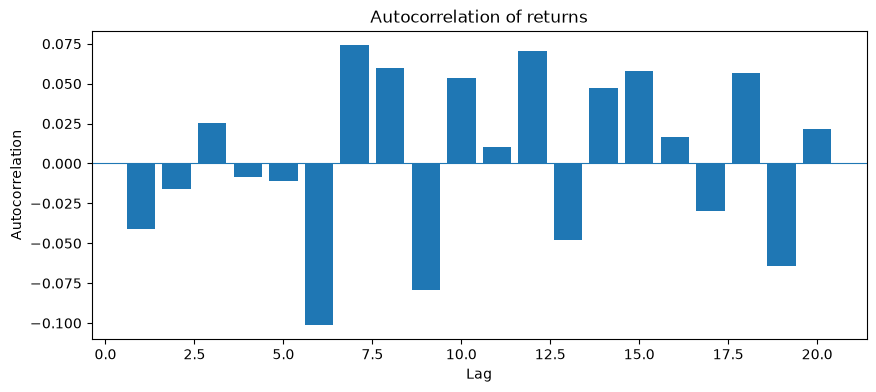

In [11]:
plt.figure(figsize=(10, 4))

plt.bar(lags, acf_returns)

plt.axhline(0, linewidth=0.8)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of returns")

plt.show()

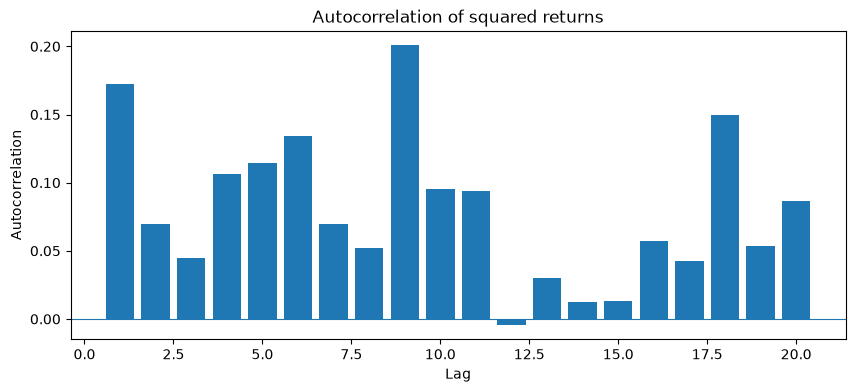

In [12]:
plt.figure(figsize=(10, 4))

plt.bar(lags, acf_squared_returns)

plt.axhline(0, linewidth=0.8)
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of squared returns")

plt.show()

## 7. Persistence of latent volatility

The parameter $\phi$ controls the persistence of the latent log-volatility.

After centering the TGA-SV process around its unconditional mean, $h_t$ behaves as an AR(1) process with autoregressive coefficient $\phi$.

Therefore,

$$
\operatorname{Corr}(h_t,h_{t-k})=\phi^k.
$$

For this simulation,

$$
\phi=0.98,
$$

which implies highly persistent volatility.

In [13]:
for lag in [1, 2, 5, 10, 20]:
    empirical = df["h"].autocorr(lag=lag)
    theoretical = 0.98 ** lag

    print(
        f"Lag {lag:2d} | "
        f"empirical = {empirical:.3f} | "
        f"phi^lag = {theoretical:.3f}"
    )

Lag  1 | empirical = 0.964 | phi^lag = 0.980
Lag  2 | empirical = 0.924 | phi^lag = 0.960
Lag  5 | empirical = 0.830 | phi^lag = 0.904
Lag 10 | empirical = 0.676 | phi^lag = 0.817
Lag 20 | empirical = 0.412 | phi^lag = 0.668


## 8. Asymmetric response to return shocks

The TGA-SV model introduces the response function

$$
f(\epsilon_t)
=
\alpha I(\epsilon_t<0)
+
\gamma_1\epsilon_t
+
\gamma_2
\left(
|\epsilon_t|-E|\epsilon_t|
\right).
$$

This function determines how the current return innovation affects future log-volatility.

Because of the threshold and asymmetric terms, negative and positive shocks of similar magnitude can have very different effects on $h_{t+1}$.

In [14]:
negative = df[df["epsilon"] < 0]
positive = df[df["epsilon"] >= 0]

print(
    "Mean f(epsilon) for negative shocks:",
    negative["f_epsilon"].mean()
)

print(
    "Mean f(epsilon) for positive shocks:",
    positive["f_epsilon"].mean()
)

Mean f(epsilon) for negative shocks: 0.13340400568352137
Mean f(epsilon) for positive shocks: -0.06440876449173742


### TGA response function

Plotting $f(\epsilon_t)$ against $\epsilon_t$ directly illustrates the asymmetry introduced by the TGA specification.

Negative shocks are expected to increase future volatility more strongly than positive shocks of comparable magnitude.

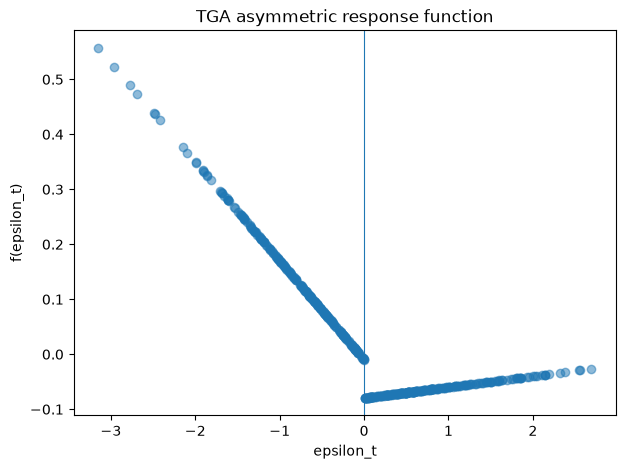

In [15]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df["epsilon"],
    df["f_epsilon"],
    alpha=0.5
)

plt.axvline(0, linewidth=0.8)

plt.xlabel("epsilon_t")
plt.ylabel("f(epsilon_t)")
plt.title("TGA asymmetric response function")

plt.show()

## 9. Conclusion

The simulation exhibits the main properties expected from the TGA-SV model:

- approximately standardized return innovations;
- stochastic and persistent latent volatility;
- volatility clustering in the observed returns;
- strong persistence driven by $\phi$;
- an asymmetric response of future volatility to return shocks.

These checks validate the simulation procedure before using the simulated returns to test the ABC filtering and parameter estimation algorithms.